# ¿Aporta la LSTM más información que el precio de Kalshi?

**Aprendizaje Automático II · BTC15M**

Estimamos una probabilidad de YES por contrato a **T−5 min**. El estudio principal agrupa cuatro pruebas mensuales, de mayo a agosto de 2026. En cada corte volvemos a entrenar con la historia disponible. Después aislamos el aporte de BRTI en el tramo que tiene cobertura del índice.

El cuaderno recorre la selección de la muestra, la alineación, los controles, la evaluación probabilística y la simulación de costes. Las salidas guardadas corresponden al histórico. El modo de demostración usa datos ficticios para comprobar el flujo.

In [1]:
%matplotlib inline
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from btc15m.brti import load_brti, without_brti
from btc15m.datos import load_data
from btc15m.evaluacion import paired_log_loss, replay, scores
from btc15m.graficos_walkforward import comparison_plot, coverage_plot
from btc15m.modelos import fit_models
from btc15m.protocolo import PERIODS
from btc15m.walkforward import coverage_table, demo_history, evaluate, load_history

modo = os.getenv("BTC15M_MODO", "historico")
if modo not in ("historico", "demo"):
    raise ValueError("Elegí BTC15M_MODO=historico o BTC15M_MODO=demo.")
ruta = Path(os.getenv("BTC15M_DATOS", "data"))
display(Markdown(f"**Modo de esta ejecución · {modo.upper()}**"))
pd.options.display.float_format = "{:.6f}".format

def mostrar(figura):
    display(figura)
    plt.close(figura)

def es(valor, decimales=6):
    return f"{valor:.{decimales}f}".replace(".", ",").replace("-", "−")

nombres = {"mercado": "Kalshi", "mercado_calibrado": "Kalshi recalibrado",
           "logistica": "Logística", "lstm": "LSTM"}

**Modo de esta ejecución · HISTORICO**

## 1. Datos y pregunta

El contrato KXBTC15M liquida en USD según el resultado oficial de Kalshi. **YES** equivale a 1 y **NO** a 0. Al estimar probabilidades, el punto medio entre las puntas de YES es una referencia exigente: ya incorpora la información del mercado.

- **Kalshi.** Observaciones del panel histórico de desarrollo con una fila por contrato a T−5. Exigimos dos puntas válidas, contrato activo y spread de hasta 5¢. El panel combina ventanas seleccionadas de velas con una captura de aproximadamente 1 Hz. Conservamos la fuente para medir si cambia el desempeño.
- **Binance BTCUSDT.** Usamos 30 velas de un minuto. Cada paso contiene retorno logarítmico, rango, logaritmo del volumen y fracción compradora. El último cierre espera un segundo para aproximar disponibilidad.
- **BRTI.** Es el índice de referencia de liquidación. Usamos la distancia logarítmica entre su media de 60 segundos antes de decidir y el umbral conocido en ese momento. Se estudia en una segunda comparación sobre contratos con ventana BRTI completa.

El panel de desarrollo abarca enero–agosto y tiene huecos. Cada vigencia mensual se informa con **contratos y días observados**. Una fila disponible debe cumplir las reglas del panel y del ejercicio. Los meses con poca captura conservan ese límite. [Archivos y procedencia](data/README.md)

### Alineación y separación temporal

La decisión queda fijada cinco minutos antes del vencimiento. El corte externo es el menor entre la hora atribuida a la cotización y un segundo antes de decidir. Las velas de Binance entran cuando su hora de cierre más un segundo es anterior o igual al corte. Una vela aún abierta al observar Kalshi queda fuera.

En cada prueba mensual, todo lo anterior al mes de validación forma el entrenamiento y el mes inmediatamente anterior se usa para validar. Se purgan las ventanas que cruzan el inicio de la etapa. Las etiquetas de entrenamiento y validación deben haberse liquidado antes del siguiente corte. El histórico se separa por contratos y fechas. El régimen de disponibilidad reconstruye el reloj con los sellos que conserva el archivo.

In [2]:
historia = demo_history() if modo == "demo" else load_history(ruta / "historico")
cobertura = coverage_table(historia)
display(cobertura)
print("Tensores de entrada [contratos, pasos, variables]", historia.sequence.shape)
if modo == "historico":
    assert (historia.frame["btc_last_close_ns"] + 10**9 <= historia.frame["info_ns"]).all()

,contratos,dias,Velas Kalshi P3,Captura Kalshi 1 Hz,Velas Kalshi P1
mes,,,,,
2026-01,327,4,327,0,0
2026-02,361,4,361,0,0
2026-03,352,4,352,0,0
2026-04,383,4,383,0,0
2026-05,383,4,383,0,0
2026-06,622,11,276,346,0
2026-07,1609,20,0,1609,0
2026-08,2137,24,0,1185,952


Tensores de entrada [contratos, pasos, variables] (6174, 30, 4)


## 2. Una arquitectura y tres controles

La **LSTM many-to-one** tiene 12 unidades ocultas. Su estado final se combina con el spread, el retorno desde apertura y el logit de Kalshi. La salida aprende una corrección al logit de mercado. Por cada contrato genera una sola probabilidad. La comparación BRTI agrega un cuarto valor al contexto.

| Control | Qué mide |
|---|---|
| Kalshi | Si el modelo supera el precio de mercado en el mismo instante. |
| Kalshi recalibrado | Si alcanza con corregir el precio mediante un ajuste logístico de una variable. |
| Regresión logística | Si la LSTM mejora un modelo lineal con las mismas variables, usando la ventana aplanada. |

En cada corte estandarizamos con el entrenamiento. En validación elegimos la penalización logística y la época de la LSTM. AdamW usa tasa 0,003, lotes de 64 y paciencia de siete hasta un máximo de 40 épocas. Promediamos tres semillas de la misma arquitectura. [Implementación](btc15m/modelos.py)

,mes_prueba,inicio_validacion,fin_test_exclusivo,n_train,dias_train,n_val,dias_val,n_test,dias_test
0,2026-05,2026-04-01,2026-06-01,1040,12,383,4,383,4
1,2026-06,2026-05-01,2026-07-01,1423,16,383,4,622,11
2,2026-07,2026-06-01,2026-08-01,1806,20,622,11,1606,20
3,2026-08,2026-07-01,2026-09-01,2428,31,1606,20,2134,24


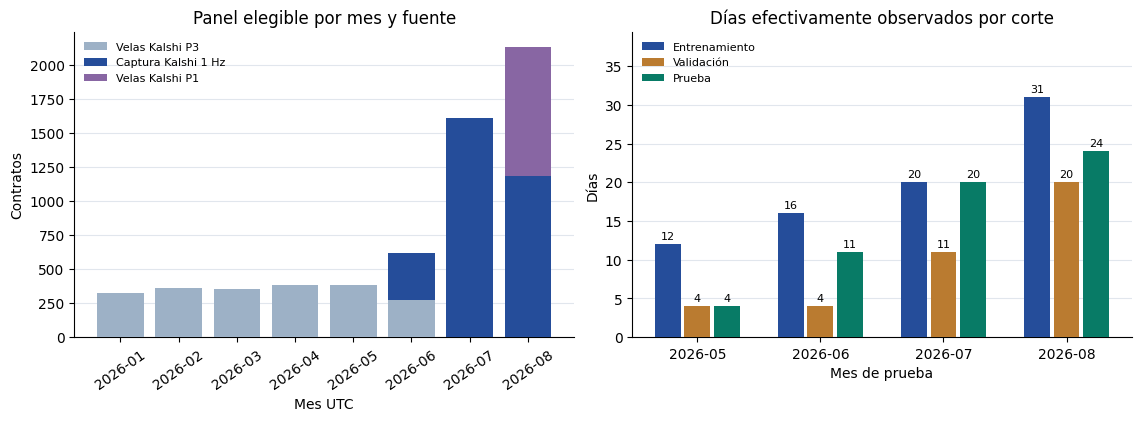

**Figura 1.** El panel izquierdo separa fuentes. El derecho distingue días observados de meses de calendario.

,mes_prueba,semilla,epoca_elegida,val_log_loss
0,2026-05,11,7,0.332626
1,2026-05,41,12,0.331935
2,2026-05,71,8,0.332106
3,2026-06,11,1,0.342830
4,2026-06,41,1,0.342610
5,2026-06,71,1,0.342873
6,2026-07,11,8,0.374609
7,2026-07,41,7,0.374574
8,2026-07,71,1,0.374970
9,2026-08,11,5,0.359149


In [3]:
resultado = evaluate(historia)
display(resultado.folds)
mostrar(coverage_plot(cobertura, resultado.folds))
display(Markdown("**Figura 1.** El panel izquierdo separa fuentes. El derecho distingue días observados de meses de calendario."))
display(resultado.selection[["mes_prueba", "semilla", "epoca_elegida", "val_log_loss"]])

## 3. ¿Mejora las probabilidades?

La métrica principal es *log loss*. Medimos diferencias pareadas sobre los mismos contratos y reportamos intervalos remuestreando días completos. Los gráficos muestran si el signo se sostiene por mes. También reportamos Brier y AUC para distinguir calidad probabilística y capacidad de ordenar contratos.

,modelo,n,dias,log_loss,brier,auc,delta_mercado
0,Kalshi,4745,59,0.368322,0.116093,0.916212,0.000000
1,Kalshi recalibrado,4745,59,0.368528,0.116208,0.916153,0.000206
2,Logística,4745,59,0.369450,0.116711,0.915568,0.001128
3,LSTM,4745,59,0.368049,0.116199,0.916225,-0.000273


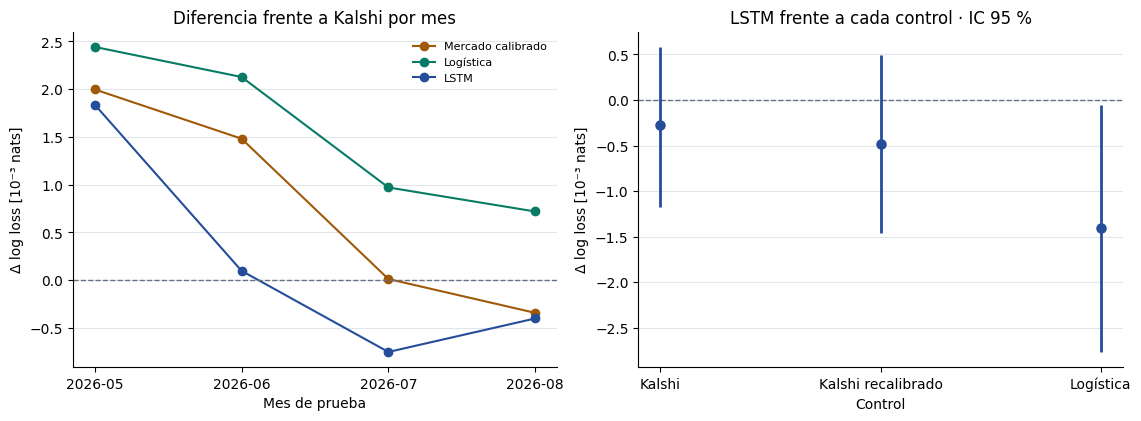

**Figura 2.** El eje cero representa igualdad. Un valor negativo indica menor log loss para el modelo.

,modelo,control,delta,ic95_inf,ic95_sup,n,dias
0,LSTM,Kalshi,-0.000273,-0.001170,0.000583,4745,59
1,LSTM,Kalshi recalibrado,-0.000479,-0.001458,0.000496,4745,59
2,LSTM,Logística,-0.001402,-0.002765,-0.000059,4745,59


,fuente,n,dias,delta_mercado,ic95_mercado_inf,ic95_mercado_sup
3,Velas Kalshi P3,659,7,0.001338,-0.000167,0.003269
7,Captura Kalshi 1 Hz,3134,42,-0.000455,-0.001422,0.000511
11,Velas Kalshi P1,952,10,-0.000790,-0.003325,0.001675


Los cortes evalúan **4,745 contratos en 59 días**. La diferencia LSTM menos Kalshi es **−0,000273 nats**, con IC 95 % **[−0,001170 a 0,000583]**.

In [4]:
total = resultado.pooled.copy()
total["modelo"] = total["modelo"].map(nombres)
display(total[["modelo", "n", "dias", "log_loss", "brier", "auc", "delta_mercado"]])
mostrar(comparison_plot(resultado))
display(Markdown("**Figura 2.** El eje cero representa igualdad. Un valor negativo indica menor log loss para el modelo."))
display(resultado.contrasts.assign(modelo=lambda t:t.modelo.map(nombres), control=lambda t:t.control.map(nombres)))
display(resultado.by_source.query('modelo == "lstm"')[["fuente", "n", "dias", "delta_mercado", "ic95_mercado_inf", "ic95_mercado_sup"]])

referencia = resultado.contrasts.query('control == "mercado"').iloc[0]
display(Markdown(
    f"Los cortes evalúan **{int(referencia.n):,} contratos en {int(referencia.dias)} días**. "
    f"La diferencia LSTM menos Kalshi es **{es(referencia.delta)} nats**, "
    f"con IC 95 % **[{es(referencia.ic95_inf)} a {es(referencia.ic95_sup)}]**."
))

### Lectura histórica

Con el panel registrado, la LSTM obtuvo **0,368049** de log loss frente a **0,368322** de Kalshi. El intervalo de la diferencia incluye cero. Frente a la logística, la diferencia pareada es **−0,001402 nats**, con un IC 95 % cuyo límite superior queda muy cerca de cero. Es evidencia modesta de mejora frente al control lineal en esta muestra. La diferencia frente a Kalshi cambia según la fuente y la fecha. Como las fuentes cubren períodos distintos, esas diferencias describen el panel y no aíslan un efecto causal de la fuente.

Los cortes son retrospectivos y el remuestreo condiciona en los modelos ajustados. Los estratos de sólo cuatro días tienen menor respaldo que los meses con mayor cobertura.

## 4. ¿Cuánto agrega el índice BRTI?

El índice disponible empieza en junio y tiene huecos. Para medir su aporte, usamos una comparación aparte con las mismas filas de entrenamiento, validación y prueba para ambas versiones de la LSTM. El ajuste utiliza el mismo procedimiento de selección que el estudio principal. La prueba focal contiene **1.182 vencimientos** de agosto.

Un tick queda disponible en el mayor sello de origen o recepción más un segundo. En cada paso de una grilla de 60 segundos tomamos el último tick disponible, con antigüedad máxima de 3 s. A partir de los 60 pasos válidos medimos la distancia entre la media del índice y el umbral del contrato. Esa media es previa a la decisión. La etiqueta proviene de la liquidación posterior. [Alineación BRTI](btc15m/brti.py)

In [5]:
if modo == "historico":
    base = load_data(ruta)
    muestras = load_brti(ruta, base)
    display(pd.DataFrame([
        {"etapa": p.label, "vencimientos_base": len(base.splits[p.key].frame),
         "con_BRTI": len(muestras[p.key].frame)} for p in PERIODS
    ]))
    train, val, test = (muestras[k] for k in ("train", "val", "test"))
    con, _, _ = fit_models(train, val)
    sin, _, _ = fit_models(without_brti(train), without_brti(val))
    pred = con.predict(test)
    pred["lstm_binance"] = sin.predict(without_brti(test))["lstm"]
    aporte = paired_log_loss(test, pred, [("lstm", "lstm_binance")]).iloc[0]
    display(Markdown(
        f"La diferencia al agregar BRTI es **{es(aporte.delta)} nats**, "
        f"con IC 95 % **[{es(aporte.ic95_inf)} a {es(aporte.ic95_sup)}]**."
    ))
else:
    display(Markdown("La comparación BRTI corresponde a la ejecución histórica guardada."))

,etapa,vencimientos_base,con_BRTI
0,Entrenamiento,1380,1375
1,Validación,572,571
2,Prueba principal,1182,1182
3,Transferencia,949,577


La diferencia al agregar BRTI es **0,000002 nats**, con IC 95 % **[−0,000169 a 0,000236]**.

En esta cohorte, el índice es la referencia correcta por la regla del contrato. La pequeña diferencia observada cabe dentro de la incertidumbre. El punto medio de Kalshi ya contiene una señal fuerte. La comparación mide si agregar **esta representación** de BRTI mejora esa señal con el reloj fijado.

## 5. ¿Alcanza después de costes?

Simulamos una unidad YES o NO a la punta observada. La tarifa del escenario es 0,07 × precio × (1 − precio), redondeada al centavo superior. Exigimos **2¢ de excedente esperado** después de costes. El escenario adverso encarece un centavo la misma compra. Los cierres de velas sirven como proxy de la punta y la simulación presupone ejecución a ese precio. Los resultados no certifican capacidad ni liquidez.

In [6]:
cuentas = resultado.paper.groupby("modelo", sort=False)[
    ["intenciones", "neto_usd", "neto_estres_usd"]
].sum().rename(index=nombres)
display(cuentas)
display(resultado.paper.query('modelo == "lstm"')[["mes_prueba", "intenciones", "neto_usd", "neto_estres_usd"]])

,intenciones,neto_usd,neto_estres_usd
modelo,,,
Kalshi,0,0.000000,0.000000
Kalshi recalibrado,0,0.000000,0.000000
Logística,372,-13.205000,-16.925000
LSTM,72,-3.320000,-4.040000


,mes_prueba,intenciones,neto_usd,neto_estres_usd
3,2026-05,42,-3.310000,-3.730000
7,2026-06,0,0.000000,0.000000
11,2026-07,14,-1.240000,-1.380000
15,2026-08,16,1.230000,1.070000


## 6. Conclusión

Ampliar la evaluación a cuatro meses ayuda a separar una pequeña mejora puntual de un patrón que se mantiene. En el histórico, la LSTM supera levemente a la logística en comparación pareada y queda cerca de Kalshi. El añadido BRTI no muestra una diferencia distinguible de cero en su comparación focal. La simulación de toda la prueba registra **72 compras, −3,32 USD netos** y **−4,04 USD** con el centavo adicional. La mejora de predicción observada frente al control lineal no se traduce en evidencia de rentabilidad.

La historia adicional es útil incluso con un resultado económico negativo. Obliga a mostrar cuántos días hay realmente detrás de cada mes y qué pasa cuando cambia la fuente de cotización. [Reproducción](README.md)